In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
def PSPL4(t, t_max, t_E, u_min, I0):
    """
    4 parameter PSPL Model for Microlensing
    returns the aparrent magnitude m given;
    t: time [HJD]
    t_max: max time [HJD]
    t_E: Crossing time [HJD]
    u_min: minimum seperation
    I0: Base magnitude
    """
    #angular seperation between lens and source (u)
    u= np.sqrt(u_min**2 + ((t - t_max) / t_E)**2)
    
    #magnification (A)
    A= (u**2 + 2) / (u*np.sqrt(u**2 + 4))
    
    #apparent magnitude
    return I0 - 2.5* np.log10(A)

In [31]:
def PSPL5(t, t_max, tE, u0, I0, fs):
    """
    4 parameter PSPL Model for Microlensing
    returns the aparrent magnitude m given;
    t: time [HJD]
    t_max: max time [HJD]
    t_E: Crossing time [HJD]
    u_min: minimum seperation
    I0: Base magnitude
    fs: blending fraction 
    """
    u = np.sqrt(u0**2 + ((t-t_max)/tE)**2)
    A = (u**2 + 2)/(u*np.sqrt(u**2 + 4))

    return I0 - 2.5*np.log10(fs*A + (1-fs))

In [3]:
def import_data(filepath):
    """
    Returns a pandas data frame given the file path for microlensing OGLE data
    """
    df= pd.read_csv(
        filepath + "/phot.dat",
        sep=r"\s+",
        header=None,
        names=["HJD", "Magnitude (I-Band)", "Mag_Error",
               "Seeing Estimation (pixels)", "Sky Level"]
    )
    return df

In [24]:
df1 = import_data("blg-0001")
df3= import_data("blg-0003")
df0843= import_data("blg-0843")

df3.head()

,HJD,Magnitude (I-Band),Mag_Error,Seeing Estimation (pixels),Sky Level
0,2.455261e+06,18.937,0.046,4.28,565.0
1,2.455261e+06,19.051,0.054,4.13,745.0
2,2.455262e+06,19.028,0.060,4.98,573.0
3,2.455263e+06,18.874,0.121,6.34,2055.0
4,2.455265e+06,19.021,0.055,5.01,492.0


In [35]:
def curveFitting(df, give_values= False, show_plot= False, name= "Untitled"):
    """
    Determines the parameters of the PSPL microlensing model given a pandas data frame
    containing I-band magnitudes and time of observation [HJD] by fitting the PSPL model to 
    the given data
    
    df: dataframe
    give_vales: boolean to determine whether you want the outputs returned
    show_plot: boolean to determine whether you want the data ploted against the model and residuals
    name: the name you want to save the plotted figure as
    """
    
    
    t = df['HJD'].values - 2450000
    mag = df['Magnitude (I-Band)'].values
    mag_err = df['Mag_Error'].values
    #Estimate tmax
    t_m_guess= df.loc[df['Magnitude (I-Band)'].idxmin()]["HJD"] - 2450000
    
    #Estimate I0
    if (t_m_guess - t[0]) > (t[-1] - t_m_guess):
        I0_g= mag[0]
    else:
        I0_g= mag[-1]
    
    #Estimate Amax
    mag_min= mag.min()
    A_max_g= 10**((I0_g - mag_min)/ 2.5)#14.8 for df1
    #A_max_g, mag_min

    #Estimate umin
    u_min_g= np.sqrt(2* (A_max_g / np.sqrt(A_max_g**2 - 1) -1))
    
    #tmax, tE, umin, I0
    initial_guess= [t_m_guess, 1, u_min_g, I0_g]


    popt, pcov= curve_fit(
        PSPL4,
        t,
        mag,
        p0= initial_guess,
        sigma= mag_err,
        absolute_sigma= True,
        #bounds= ([0, -np.inf, 0, 0], [np.inf, np.inf, np.inf, np.inf])
    )
    t_max, t_E, u_min, I0 = popt
    errors = np.sqrt(np.diag(pcov))
    
    ###Residuals
    
    mag_predicted = PSPL4(t, *popt)
    residuals = mag  - mag_predicted
    standardized_residuals = residuals / mag_err
    
    ###Plot fit and residuals
    if show_plot:
        fig, ax= plt.subplots(1, 2, figsize= (15, 6))
        fig.supxlabel("HJD - 2450000")
    
        ax[0].scatter(t, mag, color= "green", alpha= 0.5, label= "Observed Data")
        ax[0].invert_yaxis()
        ax[0].set_ylabel("I Band Magnitude")
    
        t_dummy= np.linspace(t.min(), t.max(), len(t))
        ax[0].plot(t_dummy, PSPL4(t_dummy, *popt), color= "purple", label= "PSPL Model") 
        ax[0].set_title('Microlensing Model Fitted to Data')
        ax[0].legend()
    
        ax[1].scatter(t, standardized_residuals, s=8, label= "residuals")
        ax[1].axhline(0, color='red', linestyle='--', label= "zero line")
        ax[1].set_ylabel('Standardized Residual')
        ax[1].set_title('Standardized Microlensing Residuals')
        ax[1].legend()
        
        plt.savefig(name + ".png")
    
    
    ### chi^2 and errors
    
    chi_squared = np.sum((residuals / mag_err)**2)
    dof = len(mag) - len(popt)
    reduced_chi_squared = chi_squared / dof
    
    print("The fit has the parameters")
    print("tmax:", t_max)
    print("tE:", abs(t_E))
    print("umin:", abs(u_min))
    print("I0:", I0)
    print("with uncertainties ", errors)
    print("and Reduced chi squared", reduced_chi_squared)
    
    if give_values:
        #t_max, t_E, u_min, I0
        return popt

In [41]:
def fitPSPL5(df, give_values= False, show_plot= False, name= "Untitled"):
    """
    Determines the parameters of the PSPL microlensing model given a pandas data frame
    containing I-band magnitudes and time of observation [HJD] by fitting the PSPL model to 
    the given data
    
    df: dataframe
    give_vales: boolean to determine whether you want the outputs returned
    remove_rows: list of indexes for rows you would like removed before fit
    show_plot: boolean to determine whether you want the data ploted against the model and residuals
    name: the name you want to save the plotted figure as
    """
    
    t = df['HJD'].values - 2450000
    mag = df['Magnitude (I-Band)'].values
    mag_err = df['Mag_Error'].values
    #Estimate tmax
    t_m_guess= df.loc[df['Magnitude (I-Band)'].idxmin()]["HJD"] - 2450000
    
    #Estimate I0
    if (t_m_guess - t[0]) > (t[-1] - t_m_guess):
        I0_g= mag[0]
    else:
        I0_g= mag[-1]
    
    #Estimate Amax
    mag_min= mag.min()
    A_max_g= 10**((I0_g - mag_min)/ 2.5)#14.8 for df1
    #A_max_g, mag_min

    #Estimate umin
    u_min_g= np.sqrt(2* (A_max_g / np.sqrt(A_max_g**2 - 1) -1))
    
    #tmax, tE, umin, I0
    initial_guess= [t_m_guess, 1, u_min_g, I0_g, 1]
    
    
    popt, pcov= curve_fit(
        PSPL5,
        t,
        mag,
        p0= initial_guess,
        sigma= mag_err,
        absolute_sigma= True,
        bounds= ([0, -np.inf, -np.inf, 0, 0], 
                 [np.inf, np.inf, np.inf, np.inf, 1])
    )
    t_max, t_E, u_min, I0, fs = popt
    errors = np.sqrt(np.diag(pcov))
    
    ###Residuals
    mag_predicted = PSPL5(t, *popt)
    residuals = mag  - mag_predicted
    standardized_residuals = residuals / mag_err
    
    ### chi^2 and errors
    chi_squared = np.sum((residuals / mag_err)**2)
    dof = len(mag) - len(popt)
    reduced_chi_squared = chi_squared / dof
    
    ###Plot fit and residuals
    if show_plot:
        fig, ax= plt.subplots(1, 2, figsize= (15, 6))
        fig.supxlabel("HJD - 2450000")
    
        ax[0].scatter(t, mag, color= "green", alpha= 0.5, label= "Observed Data")
        ax[0].invert_yaxis()
        ax[0].set_ylabel("I Band Magnitude")
    
        t_dummy= np.linspace(t.min(), t.max(), len(t))
        ax[0].plot(t_dummy, PSPL5(t_dummy, *popt), color= "purple", label= "PSPL Model") 
        ax[0].set_title('Microlensing Model Fitted to Data')
        ax[0].legend()
    
        ax[1].scatter(t, standardized_residuals, s=8, label= "residuals")
        ax[1].axhline(0, color='red', linestyle='--', label= "zero line")
        ax[1].set_ylabel('Standardized Residual')
        ax[1].set_title('Standardized Microlensing Residuals')
        ax[1].legend()
        
        plt.savefig(name + ".png")
        
        plt.savefig(name + ".png")
        
        print("***********************")
        print("The fit has the parameters")
        print("tmax:", t_max + 2450000)
        print("tE:", abs(t_E))
        print("umin:", abs(u_min))
        print("I0:", I0)
        print("fs:", fs)
        print("with uncertainties ", errors)
        print("and Reduced chi squared", reduced_chi_squared)

    if give_values:
        return t_max, t_E, u_min, I0, fs, reduced_chi_squared

The fit has the parameters
tmax: 5644.193161331676
tE: 52.04942326943845
umin: 0.1231945520654852
I0: 17.153783779816386
with uncertainties  [0.00705485 0.04785946 0.00010011 0.00045154]
and Reduced chi squared 517.7798476574237


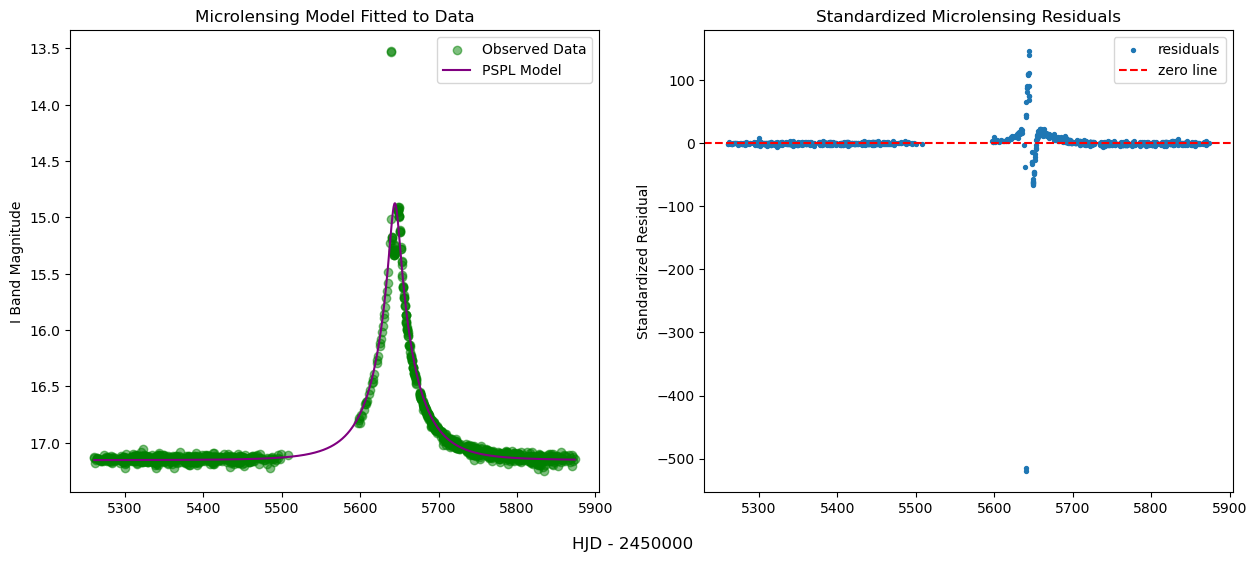

In [39]:
curveFitting(df1, show_plot= True, name= "blg1")

***********************
The fit has the parameters
tmax: 2455644.1931228195
tE: 52.049669526821006
umin: 0.12319476630926071
I0: 17.153784447344435
fs: 0.9999999999999999
with uncertainties  [0.00749862 0.21163051 0.00072072 0.00049101 0.00591363]
and Reduced chi squared 518.1330399077963


(5644.193122819648,
 52.049669526821006,
 0.12319476630926071,
 17.153784447344435,
 0.9999999999999999,
 518.1330399077963)

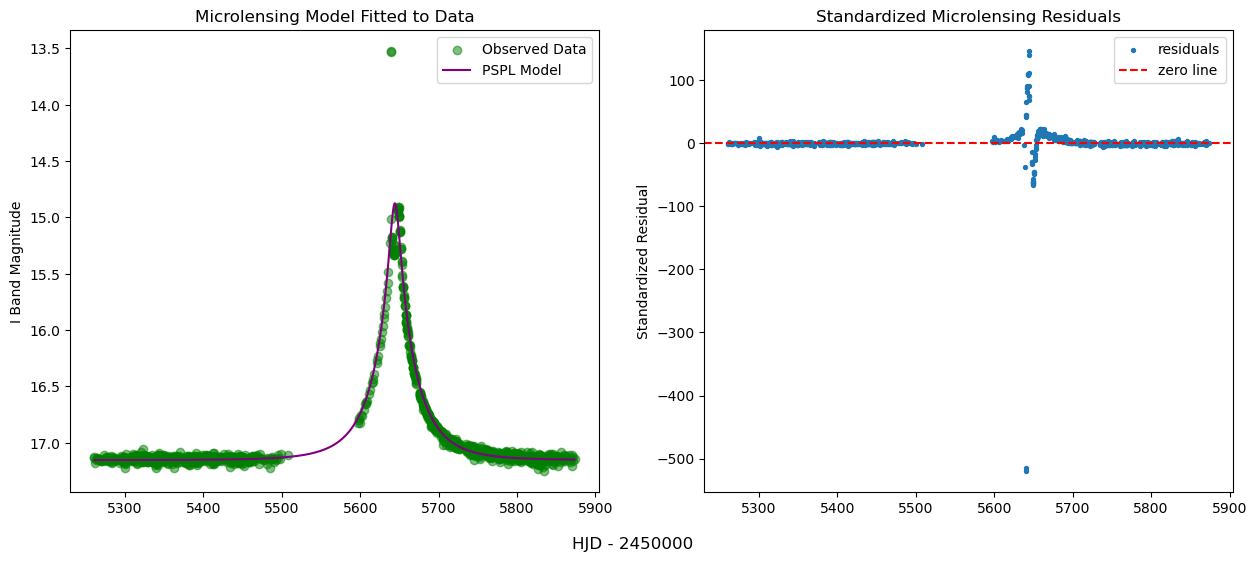

In [40]:
fitPSPL5(df1, show_plot= True)

The fit has the parameters
tmax: 5611.212059844942
tE: 34.10118644253521
umin: 0.6444108726161931
I0: 19.01706027583283
with uncertainties  [0.50408717 0.59471437 0.00641211 0.00101772]
and Reduced chi squared 2.7554809958896747


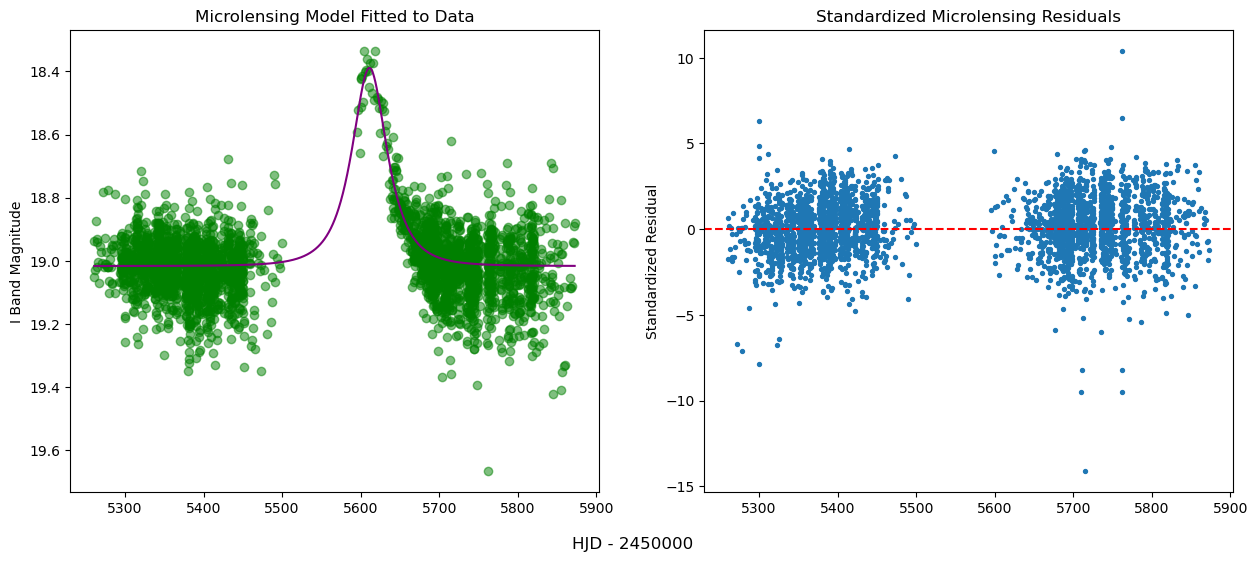

In [7]:
curveFitting(df3, show_plot= True)

The fit has the parameters
tmax: 5608.341257696186
tE: 5.528786753144348
umin: 1.017483323451949
I0: 17.206846604494242
with uncertainties  [0.13532535 0.14919253 0.01063629 0.00023006]
and Reduced chi squared 2.1518781359760135


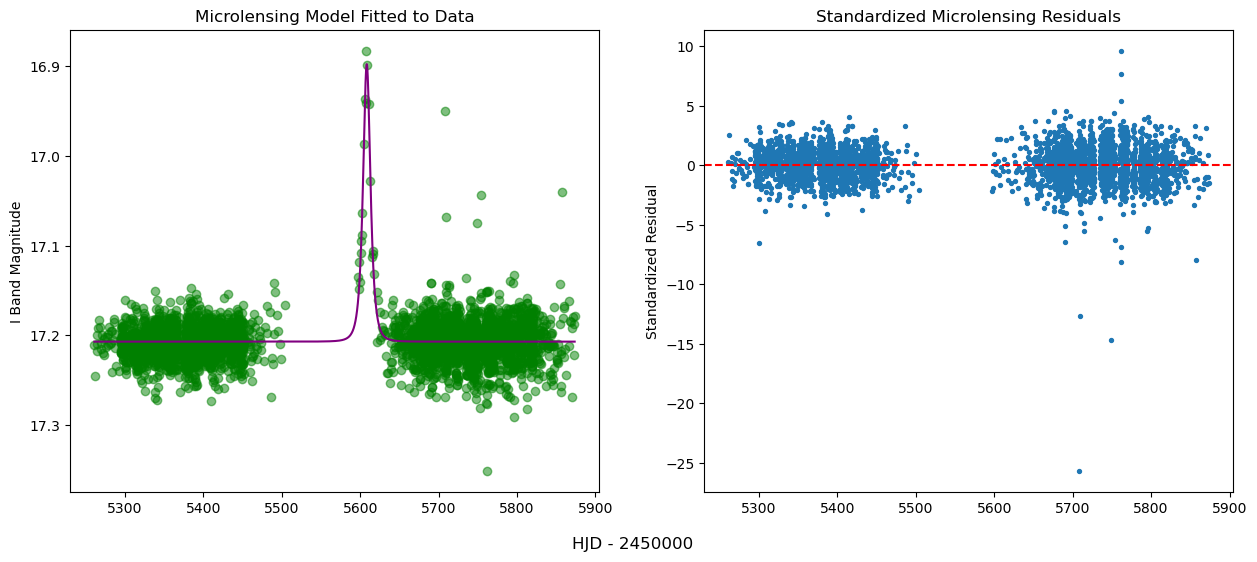

In [8]:
df34= import_data("blg-0034")
curveFitting(df34, show_plot= True)

In [9]:
#very few points around the event so not getting accurate values 

#could improve by focusing more on the event points 
#NOTE still need some pre and post event points far from event to get I0

In [12]:
#row, col= np.where(df== df['Magnitude (I-Band)'].min())

#row[0], df['Magnitude (I-Band)'][row[0]]

The fit has the parameters
tmax: 5656.008499324031
tE: 19.76659847162357
umin: 1.0366298274496004
I0: 18.798513319598726
with uncertainties  [0.54398857 0.7233307  0.01037977 0.00227442]
and Reduced chi squared 1.9094286831404028


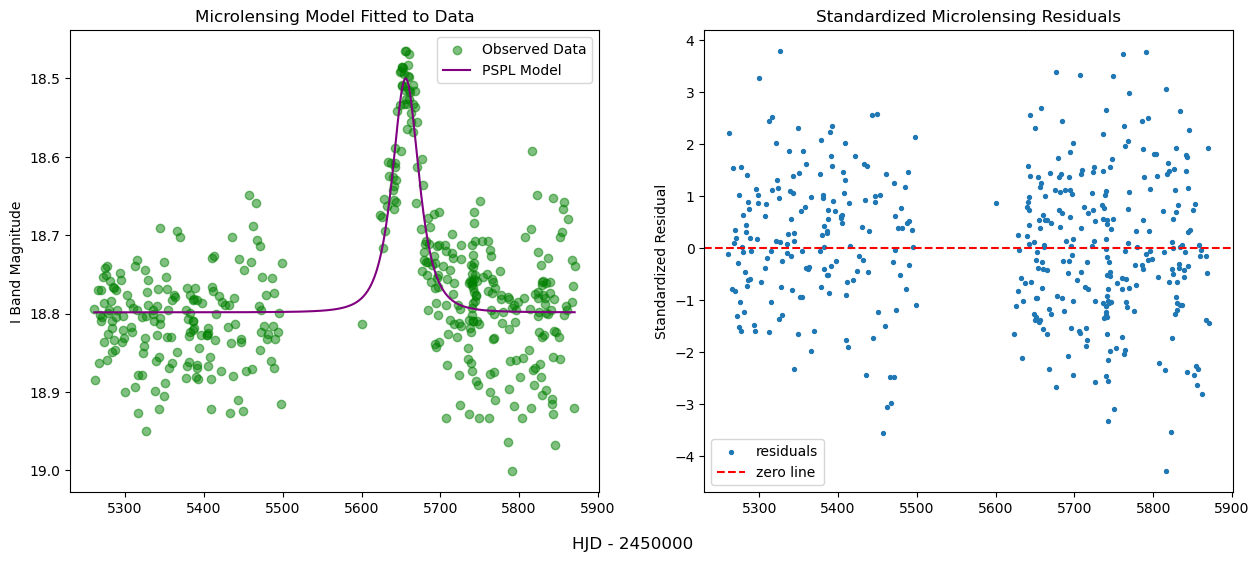

In [28]:
df207= import_data("blg-0207")
curveFitting(df207, show_plot= True, name= "blg0207")

In [ ]:
curveFitting(df0843, show_plot= True, name= "blg-0843")

The fit has the parameters
tmax: 11203.93134528759
tE: 0.9741288300847041
umin: 0.8448695554928762
I0: 18.419054273093703
with uncertainties  [0.0290918  0.03719028 0.01632944 0.00049259]
and Reduced chi squared 1.8323000443125788


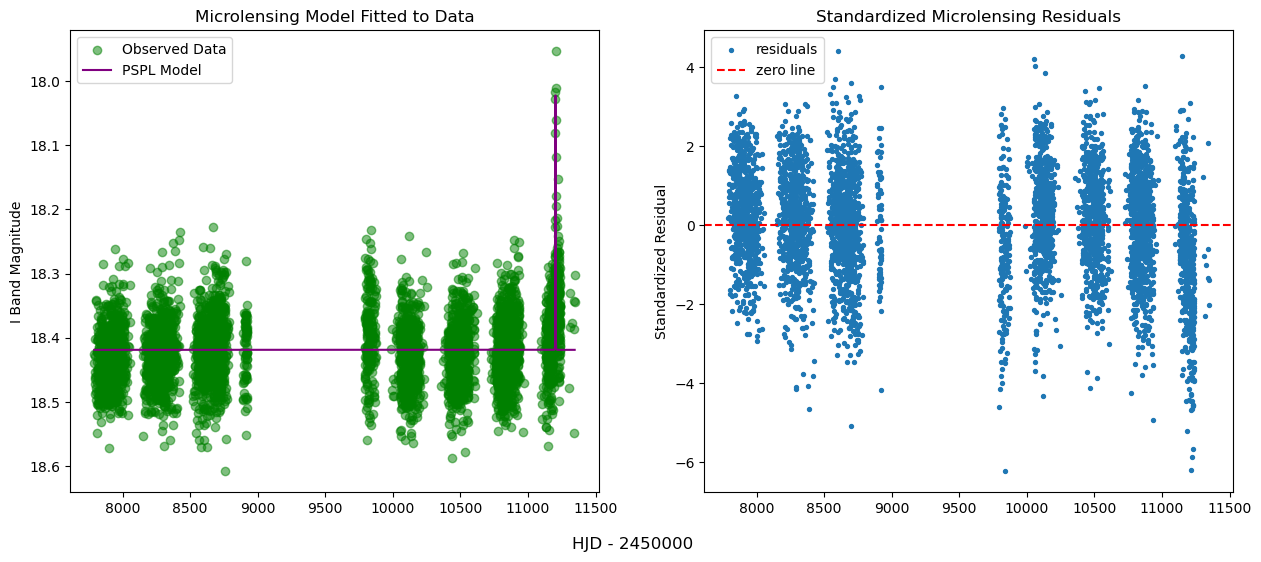

In [26]:
df0733= import_data("blg-0733")
curveFitting(df0733, show_plot= True, name= "blg-0733")